# LSST Y1 × DESI: the bias ladder under one-loop bias (model A)

The forecast fits the DESI band powers $C_\ell^{gg}$ of thin redshift bins,
computed without the Limber approximation, on four bin layouts: bins of equal
comoving width $\Delta d_\mathrm{com} = 62$ Mpc, and bins of fixed redshift width
$\Delta z = 0.02$, $0.05$ and $0.2$. Section 8 of `EXAMPLE_EVALUATE_FISHER.ipynb`
and the note `notes/correlated_bias_prior` (the v1 note) report its dark-energy
figure of merit with linear galaxy bias, as a ladder of four stated assumptions
on each bin's bias, and test every prior against random bias histories. The note
`notes/linear_bias_kmax` shows that linear bias is already biased at that cut,
$k_\mathrm{max} = 0.075\,h/\mathrm{Mpc}$.

This notebook redoes the ladder and the accuracy test with the one-loop model A
of `notes/higher_order_bias`, on the same kept band powers, so every difference
from v1 is the bias model. Its two figures are those of
`notes/correlated_bias_prior_v2`, which states the results and the
recommendation. The linear notebook stays the record of the linear-bias
analysis: nothing here writes its caches or the v1 note's folders.

**Symbols.** $D(z)$ is the linear growth factor with $D(0) = 1$;
$w(a) = w_0 + w_a(1 - a)$ the dark-energy equation of state, with $a$ the scale
factor; $\Omega_m$ the matter density today in units of the critical density;
$A_s$ the amplitude of the primordial curvature power spectrum, sampled as
`As_1e9` $= 10^9 A_s$. The figure of merit
${\rm FoM}(w_0, w_a) = [\det \mathrm{Cov}(w_0, w_a)]^{-1/2}$ is the inverse area
of the marginalized $(w_0, w_a)$ error ellipse, and $\sigma$ is a parameter's
marginalized one-sigma error.

**Model A.** As computed here, the real-space galaxy power spectrum of bin $i$ is
$$P_{gg,i}(k) = b_{1,i}^2 P_\mathrm{mm}(k) + P_\mathrm{loop}(k; b_{1,i}, b_{2,i}, b_{s^2,i})
+ \alpha_0 k^2 P_\mathrm{mm}(k) + \mathrm{SN}_0/\bar n_i ,$$
with $P_\mathrm{mm}$ the nonlinear matter power spectrum and $P_\mathrm{loop}$ the
one-loop terms. These carry the quadratic bias $b_2$, the response of the galaxy
density to the square of the matter density contrast, and the tidal bias
$b_{s^2}$, its response to the squared tidal field; the third-order bias $b_3$ is
zero. $\alpha_0$ is the $k^2$ counterterm, in $h^{-2}\,\mathrm{Mpc}^2$, and
$\mathrm{SN}_0$ the white noise beyond Poisson, in units of the bin's Poisson
power $1/\bar n_i$. The linear bias $b_{1,i}$ is per bin, under the four
linear-bias priors of the v1 ladder (growth-tied, baseline, pessimistic, free). The higher-order
biases follow it through calibrations, plus one
offset per group $g$:
$b_{2,i} = b_2^\mathrm{L}(b_{1,i}) + \Delta_{2,g}$, with $b_2^\mathrm{L}$ the
Lazeyras et al. fit (arXiv:1511.01096), and
$b_{s^2,i} = -\tfrac{4}{7}(b_{1,i} - 1) + \Delta_{s,g}$ (co-evolution). Each group
also carries one $\alpha_0$ and one $\mathrm{SN}_0$. The priors are Gaussian and
centered on zero, with widths $1$ on $\Delta_2$, $0.5$ on $\Delta_s$,
$0.5/k_\mathrm{max}^2 = 88.9\,h^{-2}\,\mathrm{Mpc}^2$ on $\alpha_0$ (a 50%
correction to the linear spectrum at $k_\mathrm{max}$) and $2$ on $\mathrm{SN}_0$.

**Two forecast variants** sit on every linear-bias prior (the labels in the code
are in parentheses):

- **model A baseline** (`'A baseline'`): one $\Delta_2$, $\Delta_s$, $\alpha_0$ and
  $\mathrm{SN}_0$ per group, with the priors above;
- **model A pessimistic** (`'A pessimistic'`): the $\Delta_2$, $\Delta_s$ and
  $\alpha_0$ of each group also tilt linearly in redshift, with flat priors on
  the tilts; $\mathrm{SN}_0$ never tilts, because its Poisson part is known bin by
  bin.

The code also computes a third configuration, **model A calibrated**
(`'A calibrated'`): the calibrations exact, no offsets,
$\alpha_0 = \mathrm{SN}_0 = 0$ fixed. It and the v1 linear-bias FoMs appear in
the printed tables as diagnostics only. Figure 1 and the results of the v2 note
are model A baseline and model A pessimistic only; the note's appendix
"Comparison with linear bias and with exact calibrations" explains why the other
two are not results.

"Baseline" and "pessimistic" name both linear-bias priors and model A
variants, so the text always says which: "the baseline prior" or "model A
baseline". The code keeps its older identifiers: `'tied'` is the growth-tied
prior and `'independent'` the free one, and a "rung" in the code is one
linear-bias prior.

**The scale cut.** Bin $i$ is cut at $k_\mathrm{max}/D(\bar z_i)$, with $\bar z_i$
its mean redshift, by the non-Limber ultraviolet-fraction criterion
(arXiv:2603.13031): a band is kept while less than $\alpha = 0.05$ of it comes
from the power spectrum above that wavenumber, within the shipped mask.
$k_\mathrm{max} = 0.075\,h/\mathrm{Mpc}$ is quoted at $z = 0$.

## 1. Set up Python and the Fisher module

Imports, the paths to CosmoLike and to the project's interface, and the figure
style shared by the project's notebooks (STIX fonts, no top or right ticks, a
faint grid). The project's Fisher module, imported as `fm`, evaluates the model A
data vectors in section 4. The Hubble distance `C_OVER_H0` ($c/H_0$ in
Mpc/$h$) is imported from the likelihood, so the counterterm uses the
likelihood's own unit conversion. The last line reports whether the CAMB halofit
tolerance patch is installed.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import json
import os
import pickle
import re
import subprocess
import sys
import time
# The OpenMP runtime reads OMP_NUM_THREADS when it starts, so the value is
# set before the Fisher module imports the compiled interface.
os.environ['OMP_NUM_THREADS'] = '8'
import numpy as np
import pandas as pd
import matplotlib
from matplotlib import pyplot as plt
from IPython.display import Image, display

# start_cocoa.sh exports ROOTDIR, the Cocoa/ folder; the EXAMPLE yamls name
# their data and codes relative to it
ROOTDIR = os.environ['ROOTDIR']
os.chdir(ROOTDIR)

sys.path.insert(0, ROOTDIR + '/external_modules/code/cosmolike_core')
sys.path.insert(0, ROOTDIR + '/projects/lssty1xdesi/interface')
import cosmolike_notebook_utils as cnu
import cosmolike_lssty1xdesi_fisher as fm
from cobaya.yaml import yaml_load_file
from cobaya.likelihoods.lssty1xdesi.desi_cl import C_OVER_H0, lazeyras_b2
print('Using the Fisher module at %s' % fm.__file__)

with open(ROOTDIR + '/external_modules/code/CAMB/fortran/halofit.f90') as f:
    HALOFIT_PATCHED = '1.d-7' in f.read()
print('CAMB halofit tolerance patch installed:', HALOFIT_PATCHED)

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams['text.usetex'] = False
pd.set_option('display.float_format', '{:.4g}'.format)


Classy could not be found in your system.
Here are some suggestions:

	 -Download the Class from class-code.net and install it
	  together with its wrapper classy (type 'make' instead of
	  'make class'
	 -If you know that Class is installed on your system
	  and yet classy could not be installed, try re-compiling
	  Class with just ''make'' instead of ''make class''
NOTICE: Even without classy you can still use EuclidEmulator2
        to emulate boost factors. You won't be able to compute
        full power spectra, though.
Using the Fisher module at /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/lssty1xdesi/interface/cosmolike_lssty1xdesi_fisher.py
CAMB halofit tolerance patch installed: True


## 2. The forecast settings

The settings fix what is compared.

- `COSMO`: the seven cosmological parameters ($10^9 A_s$, $n_s$, $H_0$, $\Omega_b$,
  $\Omega_m$, $w_0$, $w_a$), all with flat priors.
- `INVCOV_SCALE`: the DESI covariance is computed for 14,000 deg$^2$; its inverse
  is rescaled to the survey's 12,300 deg$^2$.
- `KMAX` and `LINEAR_CUTS_CACHE`: the kept band powers are the linear notebook's
  ultraviolet-fraction cuts at $k_\mathrm{max} = 0.075\,h/\mathrm{Mpc}$ (at
  $z = 0$), read from its cache, so v1 and this notebook fit the same data.
- `LSST_Y1_SRD_FOM` $= 17.26$: the LSST Y1 3x2pt reference of the `lsst_y1`
  project.
- `LAYOUTS`: the four layouts on their model A example yamls
  (`EXAMPLE_EVALUATE_MODEL_A1`–`A4.yaml`), with the linear notebook's accuracy
  settings.
- `MODEL_A_PRIOR`: the Gaussian widths of $\Delta_2$, $\Delta_s$, $\alpha_0$ and
  $\mathrm{SN}_0$. `TILT_OF` names the tilt of each offset that model A
  pessimistic frees.
- `OPERATOR_STEPS`: the finite-difference steps of the per-bin derivatives of
  section 4: $1\%$ of $b_1$, $0.02$ in $b_2$ and $b_{s^2}$, and
  $5\,h^{-2}\,\mathrm{Mpc}^2$ in $\alpha_0$.
- `DERIV_CACHE` and `RECOMPUTE`: the derivatives are cached per layout in
  `chains/`. With `RECOMPUTE = False` an existing cache is read, after a check
  that it was computed with the same settings.

In [2]:
PROJECT = 'projects/lssty1xdesi/'
CHAINS = ROOTDIR + '/projects/lssty1xdesi/chains/'
DESI_DATA = ROOTDIR + '/projects/lssty1xdesi/data/'
# the figures of this notebook go to the v2 note; the v1 note is read only
NOTE_PLOTS = ROOTDIR + '/projects/lssty1xdesi/notes/correlated_bias_prior_v2/plots/'
V1_PLOTS = ROOTDIR + '/projects/lssty1xdesi/notes/correlated_bias_prior/plots/'
COSMO = ['As_1e9', 'ns', 'H0', 'omegab', 'omegam', 'w0', 'wa']
# one footprint for every probe [deg^2]; the DESI covariance files are built
# at DESI_COV_AREA_DEG2
AREA_DEG2 = 12300.0
DESI_COV_AREA_DEG2 = 14000.0
INVCOV_SCALE = AREA_DEG2/DESI_COV_AREA_DEG2
H_MAIN = 0.02
# model A's cut, h/Mpc at z = 0 (the UV-fraction criterion at k_max/D(z))
KMAX = 0.075
# The kept band powers are the linear notebook's UV-fraction cuts at KMAX,
# read from its cache: v1 and v2 fit the same data, so every difference
# between them is the bias model.
LINEAR_CUTS_CACHE = CHAINS + 'EXAMPLE_EVALUATE_FISHER_SCALE_CUTS.pkl'
# LSST Y1 3x2pt in real space, the SRD setup (lsst_y1 project)
LSST_Y1_SRD_FOM = 17.26

# The four layouts at the linear notebook's Fisher settings (likelihood
# overrides and overall accuracy boost), on their model A example yamls.
LAYOUTS = {
    'Delta d_com = 62 Mpc': {
        'yaml': PROJECT + 'EXAMPLE_EVALUATE_MODEL_A1.yaml',
        'dataset': 'lssty1xdesi_desi_dr3',
        'bias_params': PROJECT + 'likelihood/params_desi.yaml',
        'overrides': {}, 'accuracy_boost': 1.0},
    'Delta z = 0.02': {
        'yaml': PROJECT + 'EXAMPLE_EVALUATE_MODEL_A2.yaml',
        'dataset': 'lssty1xdesi_desi_dr1_dz0p02',
        'bias_params': PROJECT + 'likelihood/params_desi_dr1_dz0p02.yaml',
        'overrides': {}, 'accuracy_boost': 1.0},
    'Delta z = 0.05': {
        'yaml': PROJECT + 'EXAMPLE_EVALUATE_MODEL_A3.yaml',
        'dataset': 'lssty1xdesi_desi_dr1_dz0p05',
        'bias_params': PROJECT + 'likelihood/params_desi_dr1_dz0p05.yaml',
        'overrides': {'nonlimber_accuracyboost': 32.0}, 'accuracy_boost': 1.0},
    'Delta z = 0.2': {
        'yaml': PROJECT + 'EXAMPLE_EVALUATE_MODEL_A4.yaml',
        'dataset': 'lssty1xdesi_desi_dr1_dz0p20',
        'bias_params': PROJECT + 'likelihood/params_desi_dr1_dz0p20.yaml',
        'overrides': {'nonlimber_accuracyboost': 64.0}, 'accuracy_boost': 3.0},
}
LAYOUT_LABELS = {'Delta d_com = 62 Mpc': r'$\Delta d_\mathrm{com} = 62$ Mpc',
                 'Delta z = 0.02': r'$\Delta z = 0.02$',
                 'Delta z = 0.05': r'$\Delta z = 0.05$',
                 'Delta z = 0.2': r'$\Delta z = 0.2$'}
LAYOUT_COLORS = {'Delta d_com = 62 Mpc': 'C0', 'Delta z = 0.02': 'C3',
                 'Delta z = 0.05': 'C2', 'Delta z = 0.2': 'C1'}

# Model A's Gaussian prior widths, all centered on zero (notes/higher_order_bias,
# its recommendation section): the b2 and bs2 offsets, alpha_0 [h^-2 Mpc^2]
# at a 50% correction to the linear spectrum at KMAX, and SN0 in units of
# each bin's Poisson power. The pessimistic tilts are free.
MODEL_A_PRIOR = {'DB2': 1.0, 'DBS': 0.5, 'A0': 0.5/KMAX**2, 'SN0': 2.0}
TILT_OF = {'DB2': 'TB2', 'DBS': 'TBS', 'A0': 'TA0'}
# the steps of the per-bin operator derivatives: b1 relative, b2 and bs2
# absolute, alpha_0 in h^-2 Mpc^2
OPERATOR_STEPS = {'b1': 0.01, 'b2': 0.02, 'bs2': 0.02, 'a0': 5.0}
DERIV_CACHE = CHAINS + 'EXAMPLE_EVALUATE_FISHER_MODEL_A_DERIVATIVES_{:d}.pkl'
RECOMPUTE = False

## 3. Data files, scale cuts and the shared helpers

Small readers for the project's data files, and the helpers every later section
uses:

- `layout_covariance` reads a layout's covariance, mask, bin table and cross-pair
  list;
- `kept_entries` returns the data-vector entries the fit uses: the shipped mask
  AND the linear notebook's ultraviolet-fraction cut at `KMAX`;
- `cosmo_errors` returns the marginalized errors of `COSMO` and the FoM;
- `bias_leaders` reads which sampled `DESI_B1_<n>` each bin is tied to in the
  shipped parameter file, which defines the six bias groups (BGS, LRG1, LRG2,
  LRG3, ELG1, ELG2).

In [3]:
def read_rows(path):
    '''The data rows of a text file (lines starting with # skipped).'''
    rows = []
    for line in open(path):
        if line.strip() and not line.startswith('#'):
            rows.append(line.split())
    return rows


def dataset_entry(stem, key):
    '''The value of one "key = value" line of a .dataset file.'''
    for row in open(DESI_DATA + stem + '.dataset'):
        if row.split('=')[0].strip() == key:
            return row.split('=', 1)[1].strip()
    raise KeyError(f'{key} is not in {stem}.dataset')


def layout_covariance(key, n):
    '''The covariance of one layout as a dense matrix, with its layout.

    Arguments:
      key = a LAYOUTS key.
      n   = the length of the full data vector.

    Returns:
      dict: 'C' (n x n), 'mask' (bool, n), 'bins' and 'pairs' (rows of the
      bin table and the pair list), 'ells' and 'n_ee' (the length of the
      empty blocks in front of the clustering spectra).
    '''
    stem = LAYOUTS[key]['dataset']
    bins = read_rows(DESI_DATA + stem + '_bins.txt')
    pairs = [(int(r[0]), int(r[1])) for r in read_rows(DESI_DATA + stem + '_pairs.txt')]
    ells = np.loadtxt(DESI_DATA + dataset_entry(stem, 'ell_file')).ravel()
    mask = np.zeros(n, dtype=bool)
    for row in read_rows(DESI_DATA + dataset_entry(stem, 'mask_file')):
        mask[int(float(row[0]))] = float(row[1]) > 0
    rows = np.loadtxt(DESI_DATA + dataset_entry(stem, 'cov_file'), usecols=(0, 1, 2))
    C = np.zeros((n, n))
    i = rows[:, 0].astype(int)
    j = rows[:, 1].astype(int)
    C[i, j] = rows[:, 2]
    C[j, i] = rows[:, 2]
    n_ee = n - (len(bins) + len(pairs))*len(ells)
    return {'C': C, 'mask': mask, 'bins': bins, 'pairs': pairs, 'ells': ells,
            'n_ee': n_ee}


with open(LINEAR_CUTS_CACHE, 'rb') as f:
    LINEAR_CUTS = pickle.load(f)['cuts']


def kept_entries(key, cov):
    '''The kept data-vector entries: the shipped mask AND the linear
    notebook's UV-fraction cut at KMAX.'''
    cuts = LINEAR_CUTS[key]
    m = int(np.argmin(np.abs(np.asarray(cuts['kmax']) - KMAX)))
    if abs(cuts['kmax'][m] - KMAX) > 1e-9:
        raise RuntimeError(f'{LINEAR_CUTS_CACHE} has no cut at {KMAX}')
    mask = cov['mask'].copy()
    mask[cov['n_ee']:] &= cuts['mask'][:, :, m].ravel() > 0
    return np.where(mask)[0]


def cosmo_errors(F, names):
    '''Marginalized sigma of COSMO and FoM(w0, wa).'''
    sigma = fm.marginalized_sigma(F, names, COSMO)
    fom = cnu.get_FoM(names.index('w0'), names.index('wa'), F)
    return sigma, fom


def bias_leaders(key):
    '''leader[i] = the sampled DESI_B1_<n> that bin i + 1 is tied to.'''
    params = yaml_load_file(LAYOUTS[key]['bias_params'])
    params = params.get('params', params)
    leader = {}
    for name, spec in params.items():
        if not name.startswith('DESI_B1_'):
            continue
        value = str(spec.get('value', '')) if isinstance(spec, dict) else ''
        found = re.search(r'lambda\s+(DESI_B1_\d+)\s*:', value)
        leader[name] = found.group(1) if found else name
    return [leader[f'DESI_B1_{i + 1}'] for i in range(len(leader))]

## 4. The model A derivatives

The Fisher matrix needs the derivative of the data vector $m$ (the band powers)
with respect to every parameter. They come in three kinds.

- **Stencil derivatives** of the seven cosmological parameters, the six group
  amplitudes $B_g$ and the velocity dispersions $\sigma_v$, from a five-point
  stencil of the model A likelihood (`model.derivatives`), as in the linear
  notebook.
- **Per-bin operator columns** $\partial m/\partial b_{1,i}$,
  $\partial m/\partial b_{2,i}$, $\partial m/\partial b_{s^2,i}$ and
  $\partial m/\partial \alpha_{0,i}$, each at fixed values of the other three. A
  wrapper of the interface's `set_nuisance_bias_tidal` intercepts the per-bin
  biases the likelihood passes to CosmoLike and shifts one of them for a set of
  bins; the central difference of two evaluations gives the columns. An
  $\alpha_0$ step enters CosmoLike's $k^2$ slot, $2 b_1 b_K k^2 P_\mathrm{mm}$, as
  $b_K = \alpha_0/[2 b_1 (c/H_0)^2]$, because CosmoLike's $k$ is in units of
  $H_0/c$.
- **Stochastic columns**: the $\mathrm{SN}_0$ columns are the likelihood's exact
  templates (`stochastic_templates`), the $\ell$-independent projection of a
  constant power through the Fingers-of-God-convolved kernels. The vector is
  linear in $\mathrm{SN}_0$, so these columns are exact.

The bins shifted together form one color of a greedy coloring of the
cross-pair graph (`pair_coloring`): two bins joined by a measured cross pair
never share a color. Every spectrum then involves at most one shifted bin, so
one pair of evaluations gives the columns of every bin of that color. Every
layout needs four colors, so each operator costs eight evaluations instead of
two per bin.

The derivatives are cached per layout, the cheapest layout first, so a long run
keeps every finished layout; with the caches in `chains/` this cell only reads
them.

In [4]:
def pair_coloring(nbins, pairs):
    '''A greedy coloring of the pair graph: no pair joins two bins of one color.'''
    neighbors = [set() for _ in range(nbins)]
    for a, b in pairs:
        neighbors[a].add(b)
        neighbors[b].add(a)
    color = []
    for i in range(nbins):
        used = {color[j] for j in neighbors[i] if j < i}
        c = 0
        while c in used:
            c += 1
        color.append(c)
    return color


def spectrum_rows(nbins, pairs, nell, n_ee):
    '''rows[i] = the data-vector entries of every spectrum that involves bin i.'''
    rows = []
    for i in range(nbins):
        r = list(range(n_ee + i*nell, n_ee + (i + 1)*nell))
        for p, (a, b) in enumerate(pairs):
            if i in (a, b):
                start = n_ee + (nbins + p)*nell
                r += list(range(start, start + nell))
        rows.append(np.array(r))
    return rows


def model_a_derivatives(key):
    '''Every derivative of one layout's model A vector at the fiducial.

    Returns:
      dict: 'names', 'fiducial', 'm0', 'D' (the stencil derivatives of
      COSMO, the DESI_B1 leaders and the DESI_SIGV leaders), 'priors'
      ({name: Gaussian sigma}), the fiducial per-bin 'b1', 'b2', 'bs2',
      'ops' ({operator: (n, nbins) per-bin partial derivatives at fixed
      other operators}: 'b1' per unit b1, 'b2', 'bs2', 'a0' per unit
      alpha_0), 'T' (the SN0 columns), 'leaders', 'colors' and 'seconds'.
    '''
    s = LAYOUTS[key]
    start = time.time()
    model = fm.ModelFisher(s['yaml'], COSMO, extra_prefixes=('DESI_B1_', 'DESI_SIGV_'),
                           likelihood_overrides=s['overrides'],
                           invcov_scale=INVCOV_SCALE, accuracy_boost=s['accuracy_boost'])
    like = model.model.likelihood[model.likelihood_name]
    original = fm.ci.set_nuisance_bias_tidal
    seen = {}
    shift = {'op': None}

    def tidal(**kw):
        kw = {k: np.array(v, dtype=float) for k, v in kw.items()}
        if shift['op'] is None:
            seen.update({k: v.copy() for k, v in kw.items()})
        else:
            op, members, step = shift['op'], shift['members'], shift['step']
            if op == 'b1':
                kw['B1'][members] *= 1.0 + step
            elif op == 'b2':
                kw['B2'][members] += step
            elif op == 'bs2':
                kw['BS2'][members] += step
            elif op == 'a0':
                # alpha_0 k^2 P = 2 b1 bK k^2 P with k in H0/c units
                kw['BK'][members] += step/(2.0*kw['B1'][members]*C_OVER_H0**2)
        return original(**kw)

    fm.ci.set_nuisance_bias_tidal = tidal
    try:
        m0 = model.dv()
        b1, b2, bs2 = seen['B1'].copy(), seen['B2'].copy(), seen['BS2'].copy()
        T = like.stochastic_templates()
        cov = layout_covariance(key, len(m0))
        nbins, pairs, nell = len(cov['bins']), cov['pairs'], len(cov['ells'])
        rows = spectrum_rows(nbins, pairs, nell, cov['n_ee'])
        color = pair_coloring(nbins, pairs)
        ops = {}
        for op, step in OPERATOR_STEPS.items():
            Dop = np.zeros((len(m0), nbins))
            for c in range(max(color) + 1):
                members = np.array([i for i in range(nbins) if color[i] == c])
                vectors = []
                for sign in (1.0, -1.0):
                    shift.update(op=op, members=members, step=sign*step)
                    vectors.append(model.dv())
                shift['op'] = None
                d = (vectors[0] - vectors[1])/(2.0*step)
                for i in members:
                    # the b1 step is relative: (b1 dm/db1)/b1 = dm/db1
                    Dop[rows[i], i] = d[rows[i]]/(b1[i] if op == 'b1' else 1.0)
            ops[op] = Dop
        D = model.derivatives(h=H_MAIN)
    finally:
        fm.ci.set_nuisance_bias_tidal = original
    priors = {model.names[i]: sig for i, sig in model.prior_sigmas().items()}
    out = {'names': list(model.names), 'fiducial': np.array(model.fiducial), 'm0': m0,
           'D': D, 'priors': priors, 'b1': b1, 'b2': b2, 'bs2': bs2, 'ops': ops, 'T': T,
           'leaders': bias_leaders(key), 'colors': max(color) + 1,
           'seconds': time.time() - start}
    del model
    return out


# one cache per layout, so a long run keeps every finished layout; the
# cheapest layouts run first
COMPUTE_ORDER = ['Delta z = 0.05', 'Delta z = 0.2', 'Delta z = 0.02', 'Delta d_com = 62 Mpc']
derivs = {}
for key in COMPUTE_ORDER:
    cache = DERIV_CACHE.format(list(LAYOUTS).index(key) + 1)
    settings_now = {**LAYOUTS[key], 'steps': dict(OPERATOR_STEPS), 'h': H_MAIN}
    if RECOMPUTE or not os.path.exists(cache):
        derivs[key] = model_a_derivatives(key)
        with open(cache, 'wb') as f:
            pickle.dump({'derivs': derivs[key], 'settings': settings_now}, f)
        print(f'{key}: {derivs[key]["colors"]} bin colors, '
              f'{derivs[key]["seconds"]:.0f} s', flush=True)
    else:
        with open(cache, 'rb') as f:
            cached = pickle.load(f)
        if cached['settings'] != settings_now:
            raise RuntimeError(f'{cache} holds other settings: set RECOMPUTE = True')
        derivs[key] = cached['derivs']
derivs = {key: derivs[key] for key in LAYOUTS}

Model A ties $b_2$ and $b_{s^2}$ to $b_1$, so the per-bin columns must add up to
what the likelihood does when a group amplitude moves. A change of $B_g$ moves
the linear bias of every bin of group $g$ by $b_{1,i}/B_g = 1/D(z_i)$ per unit,
and $b_{2,i}$ and $b_{s^2,i}$ follow:
$$\frac{\partial m}{\partial B_g} = \sum_{i \in g} \frac{b_{1,i}}{B_g}\left[
\frac{\partial m}{\partial b_{1,i}}
+ b_2^{\mathrm{L}\,\prime}(b_{1,i})\,\frac{\partial m}{\partial b_{2,i}}
- \frac{4}{7}\,\frac{\partial m}{\partial b_{s^2,i}}\right],$$
with $b_2^{\mathrm{L}\,\prime}$ the slope of the Lazeyras fit (`lazeyras_slope`).
`total_b1_columns` builds each bin's bracket times $b_{1,i}/B_g$; the check
compares their sum over each group with the stencil derivative of $B_g$, on the
entries where the vector is nonzero.

In [5]:
def lazeyras_slope(b1):
    '''d b2_Lazeyras / d b1.'''
    return -2.143 + 2.0*0.929*b1 + 3.0*0.008*b1**2


def total_b1_columns(key):
    '''dm/dDESI_B1_i with b2 and bs2 following b1 (model A), per bin.'''
    der = derivs[key]
    fid = dict(zip(der['names'], der['fiducial']))
    b1 = der['b1']
    amp = np.array([fid[ld] for ld in der['leaders']])
    return (der['ops']['b1'] + der['ops']['b2']*lazeyras_slope(b1)[None, :]
            - 4.0/7.0*der['ops']['bs2'])*(b1/amp)[None, :]


check = {}
for key in LAYOUTS:
    der = derivs[key]
    B = total_b1_columns(key)
    live = der['m0'] != 0.0
    worst = 0.0
    for ld in dict.fromkeys(der['leaders']):
        idx = [i for i, x in enumerate(der['leaders']) if x == ld]
        ref = der['D'][:, der['names'].index(ld)]
        diff = B[:, idx].sum(axis=1) - ref
        worst = max(worst, float(np.max(np.abs(diff[live]))/np.max(np.abs(ref[live]))))
    check[key] = {'bin colors': der['colors'], 'max |sum - stencil| / max |stencil|': worst}
print('model A chain rule: per-bin columns summed per group against the stencil '
      'derivative of each bias amplitude')
display(pd.DataFrame(check).T)

model A chain rule: per-bin columns summed per group against the stencil derivative of each bias amplitude


,bin colors,max |sum - stencil| / max |stencil|
Delta d_com = 62 Mpc,4,9.795e-08
Delta z = 0.02,4,1.216e-07
Delta z = 0.05,4,4.011e-08
Delta z = 0.2,4,1.295e-08


**Reading the check.** On every layout the per-bin sum reproduces the stencil
derivative of each group amplitude to at most $1.2\times10^{-7}$ of the stencil
column's largest entry. The two routes are independent (operator columns
through the bias setter, the full likelihood through the stencil), so the
per-bin columns and the model A chain rule agree with the likelihood.

## 5. The Fisher matrices of model A

`model_a_fisher` assembles one Fisher matrix per layout and variant. The
parameters are, in order:

1. the cosmological parameters and the velocity dispersions, with the Gaussian
   $\sigma_v$ priors of the linear analysis;
2. the variant's higher-order parameters (`higher_order_columns`): none for model
   A calibrated; for model A baseline one $\Delta_2$, $\Delta_s$, $\alpha_0$ and
   $\mathrm{SN}_0$ per group, each column the sum of the group's per-bin columns,
   with the Gaussian widths of `MODEL_A_PRIOR`; for model A pessimistic also the
   tilt columns $\sum_{i \in g}(\bar z_i - \bar z_g)\,\partial m/\partial b_{2,i}$
   (likewise for $b_{s^2}$ and $\alpha_0$), with flat priors, in every group of
   more than one bin;
3. one amplitude `DESI_B1_<n>` per bin, $\beta_i = b_{1,i} D(z_i)$, whose column is
   the model A total derivative of section 4.

The data Fisher matrix is $F = D^\mathsf{T} C^{-1} D$ on the kept entries, with
the inverse covariance rescaled to the survey area; the Gaussian priors come back
as a diagonal. The higher-order parameters sit in front of the per-bin
amplitudes, so the ladder code of the linear notebook acts unchanged on the
amplitude block: the higher-order parameters are marginalized like the
cosmology.

In [6]:
BIAS_GROUP_NAMES = ['BGS', 'LRG1', 'LRG2', 'LRG3', 'ELG1', 'ELG2']
HO_VARIANTS = ['A calibrated', 'A baseline', 'A pessimistic']
BIN_ZBAR = {key: np.array([float(row[4]) for row in
                           layout_covariance(key, len(derivs[key]['m0']))['bins']])
            for key in LAYOUTS}
INV_KEPT = {}


def kept_inverse(key):
    '''(kept entries, inverse of the kept covariance block times INVCOV_SCALE).'''
    if key not in INV_KEPT:
        cov = layout_covariance(key, len(derivs[key]['m0']))
        kept = kept_entries(key, cov)
        INV_KEPT[key] = (kept, np.linalg.inv(cov['C'][np.ix_(kept, kept)])*INVCOV_SCALE)
    return INV_KEPT[key]


def bias_groups(key):
    '''(group name, leader name, bin indices) per bias group, BGS..ELG2.'''
    leaders = derivs[key]['leaders']
    out = []
    for name, leader in zip(BIAS_GROUP_NAMES, dict.fromkeys(leaders)):
        out.append((name, leader, np.array([i for i, x in enumerate(leaders) if x == leader])))
    return out


def higher_order_columns(key, variant):
    '''The model A columns of one variant: (columns, names, prior sigmas).'''
    der = derivs[key]
    zbar = BIN_ZBAR[key]
    cols, names, sigmas = [], [], []
    if variant == 'A calibrated':
        return np.zeros((len(der['m0']), 0)), names, sigmas
    source = {'DB2': der['ops']['b2'], 'DBS': der['ops']['bs2'],
              'A0': der['ops']['a0'], 'SN0': der['T']}
    for fam in ('DB2', 'DBS', 'A0', 'SN0'):
        for name, leader, idx in bias_groups(key):
            M = source[fam][:, idx]
            cols.append(M.sum(axis=1))
            names.append(f'DESI_{fam}_{name}')
            sigmas.append(MODEL_A_PRIOR[fam])
            if variant == 'A pessimistic' and fam in TILT_OF and len(idx) > 1:
                cols.append(M @ (zbar[idx] - zbar[idx].mean()))
                names.append(f'DESI_{TILT_OF[fam]}_{name}')
                sigmas.append(np.inf)
    return np.column_stack(cols), names, sigmas


def model_a_fisher(key, variant):
    '''The data Fisher matrix of one layout and higher-order variant, its
    diagonal prior precision, the names, and what the response needs.

    Order: COSMO and the velocity dispersions, the higher-order parameters,
    then one DESI_B1_<n> per bin (the per-bin biases last, as the ladder
    code expects).

    Returns:
      (F_data, prior_diag, names, extra) with extra = {'D': the kept rows of
      the derivative matrix, 'Cinv': the kept inverse covariance}.
    '''
    der = derivs[key]
    keep = [j for j, nm in enumerate(der['names']) if not nm.startswith('DESI_B1_')]
    H, hnames, hsig = higher_order_columns(key, variant)
    B = total_b1_columns(key)
    D = np.hstack([der['D'][:, keep], H, B])
    names = ([der['names'][j] for j in keep] + hnames
             + [f'DESI_B1_{i + 1}' for i in range(B.shape[1])])
    kept, Cinv = kept_inverse(key)
    Dk = D[kept]
    F_data = Dk.T @ Cinv @ Dk
    prior = [1.0/der['priors'][der['names'][j]]**2 if der['names'][j] in der['priors'] else 0.0
             for j in keep]
    prior += [0.0 if np.isinf(sg) else 1.0/sg**2 for sg in hsig]
    prior += [0.0]*B.shape[1]
    return F_data, np.array(prior), names, {'D': Dk, 'Cinv': Cinv}

## 6. The ladder of linear-bias models under model A

The four linear-bias priors of the v1 note, each with the three higher-order
variants, give 48 Fisher systems (four layouts, three variants, four priors):

- **growth-tied**: one amplitude per group, the bias following $1/D(z)$,
  $b_{1,i} = B_g/D(z_i)$; the per-bin amplitude columns are summed per group
  (`rung_system(..., tied=True)`);
- **baseline prior**: one amplitude per bin with v1's correlated prior
  (`group_bias_precision`): a free amplitude and tilt per group, and a residual
  of width $\sigma_g = 3\%$ for BGS and $1\%$ for the other groups, correlated over
  $L = 0.2$ in redshift;
- **pessimistic prior**: the same with $\sigma_g = 3\%$ everywhere and $L = 0.05$;
- **free**: one amplitude per bin, each with a flat prior.

`BIAS_ASSUMPTIONS` holds the two priors; they equal the v1 note's. Each enters as
the projected precision that charges only the residual around each group's line
(v1 note, appendix "The memory projection, step by step").

`stable_inverse` inverts each Fisher matrix through a pseudo-inverse. On the
62 Mpc layout at this cut only 7 of the 18 BGS bins keep data, and the
flat-prior BGS tilts of model A pessimistic leave one parameter combination with
no information on the free prior; a plain inverse amplifies round-off
along it. The matrix is scaled to unit diagonal, diagonalized, and the
directions below `PINV_RTOL` $= 10^{-12}$ of the largest eigenvalue are dropped.
The cell prints every dropped direction and its largest component on
$(w_0, w_a)$, $\Omega_m$ and $A_s$, which must vanish for a pure nuisance
combination.

Each prior then gives its ${\rm FoM}(w_0, w_a)$ and the shifts of v1's two known
bias drifts (`bias_drift`: a conserved galaxy population in every group, the
$r < 19.5$ flux limit in BGS). A shift is the Fisher linear response
$\delta p = F^{-1} D^\mathsf{T} C^{-1} \delta m$, scored as $(w_0, w_a)$ in units of
the fit's marginalized ellipse and as $\Omega_m$ and $A_s$ in their own $\sigma$.
Under model A a drift of $b_1$ moves $b_2$ and $b_{s^2}$ with it (`drift_g`). The
first table prints the FoMs of model A baseline and model A pessimistic, and,
as diagnostics, the v1 linear-bias FoMs (read from the v1 note's figure data)
and those of model A calibrated. Figure 1 and the note's results use the two
model A forecast variants only.

The cell also prints a second table, the figure of merit of the matter density
and the primordial amplitude,
${\rm FoM}(\Omega_m, 10^9 A_s) = [\det \mathrm{Cov}(\Omega_m, 10^9 A_s)]^{-1/2}$
in the sampled units. `rung_system` computes it from the same Fisher inverse
as the dark-energy FoM, so the two tables describe one fit. It feeds panel (b)
of the note's Figure 1.

In [7]:
sys.path.insert(0, V1_PLOTS)
import make_theory_data as bias_theory

BIAS_ASSUMPTIONS = {
    'baseline': {'L': 0.2, 'sigma_b': {'BGS': 0.03, 'LRG1': 0.01, 'LRG2': 0.01,
                                       'LRG3': 0.01, 'ELG1': 0.01, 'ELG2': 0.01}},
    'pessimistic': {'L': 0.05, 'sigma_b': {name: 0.03 for name in BIAS_GROUP_NAMES}},
}
LADDER_RUNGS = ['tied', 'baseline', 'pessimistic', 'independent']
DRIFT_LAWS = ['conserved', 'flux_limit']
SHIFT_THRESHOLD = 1.0/3.0
# Bias errors move the clustering amplitude, b^2 A_s D^2, and the growth
# history first: the matter density and the primordial amplitude are
# scored next to (w0, wa), each in units of its own marginalized sigma.
SINGLE_PARAMS = ['omegam', 'As_1e9']
# Directions of a Fisher matrix whose eigenvalue, after scaling every
# parameter to unit diagonal, is below this fraction of the largest carry
# no information from the data or the priors; stable_inverse drops them.
PINV_RTOL = 1.0e-12


def stable_inverse(F):
    '''The inverse of a symmetric Fisher matrix, safe when it is singular.

    A parameter set can leave a direction with no information at all: on
    the 62 Mpc layout at this cut only 7 of the 18 BGS bins keep data, and
    the flat-prior BGS tilts of model A pessimistic then leave one
    combination of them unconstrained. np.linalg.inv amplifies round-off
    along such a direction by ~1e16. Here F is scaled to unit diagonal
    (so the parameter units do not matter), diagonalized, and the
    directions below PINV_RTOL of the largest eigenvalue are dropped (a
    pseudo-inverse). A dropped direction is a pure nuisance combination
    only if it does not touch the scored parameters; the caller checks.

    Returns:
      (F_inv, null): null holds the dropped directions as columns, in the
      scaled basis (zero entries mark the parameters they leave alone).
    '''
    s = 1.0/np.sqrt(np.diag(F))
    w, V = np.linalg.eigh(F*s[:, None]*s[None, :])
    keep = w > PINV_RTOL*w.max()
    F_inv = (s[:, None]*V[:, keep]) @ np.diag(1.0/w[keep]) @ (V[:, keep].T*s[None, :])
    return F_inv, V[:, ~keep]


def fiducial_of(key):
    der = derivs[key]
    return dict(zip(der['names'], der['fiducial']))


def group_bias_precision(key, L, sigma_by_group, free_tilt=True):
    '''The memory-model prior precision on the bin biases (v1 notebook).'''
    zbar = BIN_ZBAR[key]
    fiducial = fiducial_of(key)
    P = np.zeros((len(zbar), len(zbar)))
    for name, leader, idx in bias_groups(key):
        z = zbar[idx]
        U = np.column_stack([np.ones(len(z))] + ([z - z.mean()] if free_tilt else []))
        if len(idx) <= U.shape[1]:
            continue
        width = sigma_by_group[name]*fiducial[leader]
        Q = np.linalg.inv(width**2*np.exp(-np.abs(z[:, None] - z[None, :])/L))
        QU = Q @ U
        P[np.ix_(idx, idx)] = Q - QU @ np.linalg.inv(U.T @ QU) @ QU.T
    return P


def bias_drift(key, law):
    '''The fractional deviation of every bin's b1 from B_g/D(z) under a known
    drift (v1 notebook): the higher-order biases follow b1 in the truth too.'''
    zbar = BIN_ZBAR[key]
    fiducial = fiducial_of(key)
    delta = np.zeros(len(zbar))
    for name, leader, idx in bias_groups(key):
        z = zbar[idx]
        if law == 'conserved':
            b_center = fiducial[leader]/bias_theory.growth(z.mean())[0]
            bias = bias_theory.conserved_bias(z, z.mean(), b_center)
        elif law == 'flux_limit' and name == 'BGS':
            bias = bias_theory.bgs_flux_limit_bias(z)
        else:
            continue
        delta[idx] = bias_theory.deviation_from_tied(z, bias)
    return delta


def rung_system(key, fisher, precision=None, tied=False):
    '''The Fisher matrix of one rung and the map from D^T C^-1 dm to (w0, wa).

    Returns:
      dict: 'solve' (g -> dw, g = D^T C^-1 dm over the fisher names),
      'Cw' (the marginalized w0-wa covariance), 'Nw' (its share from the data
      noise and the Gaussian priors), 'fom'.
    '''
    F_data, prior_diag, names, extra = fisher
    nbins = sum(1 for nm in names if nm.startswith('DESI_B1_'))
    nx = len(names) - nbins
    F0 = F_data + np.diag(prior_diag)
    Tm = np.eye(len(names))
    used = list(names)
    if tied:
        groups = bias_groups(key)
        Tm = np.zeros((len(names), nx + len(groups)))
        Tm[:nx, :nx] = np.eye(nx)
        for c, (name, leader, idx) in enumerate(groups):
            Tm[nx + idx, nx + c] = 1.0
        used = names[:nx] + [leader for name, leader, idx in groups]
    F0t = Tm.T @ F0 @ Tm
    F = F0t.copy()
    if precision is not None and not tied:
        F[nx:, nx:] += precision
    live = [j for j in range(len(used)) if np.any(F[j] != 0.0)]
    used_live = [used[j] for j in live]
    iw = [used_live.index('w0'), used_live.index('wa')]
    F_inv, null = stable_inverse(F[np.ix_(live, live)])
    scored = iw + [used_live.index(p) for p in SINGLE_PARAMS]
    null_overlap = float(np.max(np.abs(null[scored]))) if null.shape[1] else 0.0
    Cw = F_inv[np.ix_(iw, iw)]
    # the figure of merit of (Omega_m, 10^9 A_s), in the sampled units,
    # from the same inverse as the dark-energy one
    i_om_as = [used_live.index(p) for p in ('omegam', 'As_1e9')]
    fom_om_as = 1.0/np.sqrt(np.linalg.det(F_inv[np.ix_(i_om_as, i_om_as)]))
    Nw = (F_inv @ F0t[np.ix_(live, live)] @ F_inv)[np.ix_(iw, iw)]
    # the single parameters scored next to (w0, wa): index and marginalized sigma
    ip = {p: used_live.index(p) for p in SINGLE_PARAMS}
    sigma = {p: float(np.sqrt(F_inv[i, i])) for p, i in ip.items()}
    noise = F_inv @ F0t[np.ix_(live, live)] @ F_inv
    # the share of each parameter's variance from the data noise and the
    # Gaussian priors, in units of its own variance
    noise_single = {p: float(noise[i, i]/sigma[p]**2) for p, i in ip.items()}

    def solve(g):
        return (F_inv @ (Tm.T @ g)[live])[iw]

    def solve_single(g):
        '''{p: shift of p in units of its own marginalized sigma}.'''
        dp = F_inv @ (Tm.T @ g)[live]
        return {p: float(dp[i]/sigma[p]) for p, i in ip.items()}

    return {'solve': solve, 'solve_single': solve_single, 'Cw': Cw, 'Nw': Nw,
            'fom': 1.0/np.sqrt(np.linalg.det(Cw)), 'fom_om_as': float(fom_om_as),
            'nx': nx, 'sigma': sigma,
            'noise_single': noise_single, 'dropped': int(null.shape[1]),
            'null_overlap': null_overlap}


def drift_g(key, fisher, delta):
    '''D^T C^-1 dm of a b1 drift delta (b2 and bs2 following b1).'''
    F_data, prior_diag, names, extra = fisher
    nbins = sum(1 for nm in names if nm.startswith('DESI_B1_'))
    beta = np.array([fiducial_of(key)[x] for x in derivs[key]['leaders']])
    return F_data[:, len(names) - nbins:] @ (beta*delta)


def rung_systems(key, fisher):
    systems = {'tied': rung_system(key, fisher, tied=True),
               'independent': rung_system(key, fisher)}
    for case, prior in BIAS_ASSUMPTIONS.items():
        systems[case] = rung_system(key, fisher, precision=group_bias_precision(
            key, prior['L'], prior['sigma_b']))
    return systems


fishers, systems, drifts = {}, {}, {}
ladder = {}
for key in LAYOUTS:
    drifts[key] = {law: bias_drift(key, law) for law in DRIFT_LAWS}
    for variant in HO_VARIANTS:
        fishers[(key, variant)] = model_a_fisher(key, variant)
        systems[(key, variant)] = rung_systems(key, fishers[(key, variant)])
        for rung in LADDER_RUNGS:
            sysm = systems[(key, variant)][rung]
            Ci = np.linalg.inv(sysm['Cw'])
            shifts = {}
            for law in DRIFT_LAWS:
                g = drift_g(key, fishers[(key, variant)], drifts[key][law])
                dw = sysm['solve'](g)
                shifts[law] = float(np.sqrt(dw @ Ci @ dw))
                for p, v in sysm['solve_single'](g).items():
                    shifts[f'{law}_{p}'] = abs(v)
            ladder[(key, variant, rung)] = {'fom': float(sysm['fom']),
                                            'fom_om_as': sysm['fom_om_as'], **shifts}

# Directions without information that stable_inverse dropped, and their
# largest component on (w0, wa), Omega_m and A_s (scaled basis): a pure
# nuisance direction leaves the scored parameters alone (component ~ 0).
singular = {(key, variant, rung): systems[(key, variant)][rung]
            for key in LAYOUTS for variant in HO_VARIANTS for rung in LADDER_RUNGS
            if systems[(key, variant)][rung]['dropped']}
print(f'systems with directions without information: {len(singular)} of '
      f'{len(LAYOUTS)*len(HO_VARIANTS)*len(LADDER_RUNGS)}')
for (key, variant, rung), sysm in singular.items():
    print(f'  {key}, {variant}, {rung}: {sysm["dropped"]} dropped, largest component on the '
          f'scored parameters {sysm["null_overlap"]:.1e}')

with open(V1_PLOTS + 'baseline_ladder/data.json') as f:
    V1_LADDER = {lay['name']: lay for lay in json.load(f)['layouts']}

table = {}
for key in LAYOUTS:
    table[(key, 'v1 linear')] = {rung: V1_LADDER[key]['fom'][rung] for rung in LADDER_RUNGS}
    for variant in HO_VARIANTS:
        table[(key, variant)] = {rung: ladder[(key, variant, rung)]['fom'] for rung in LADDER_RUNGS}
print(f'FoM(w0, wa) of DESI C_gg alone at k_max = {KMAX} h/Mpc (LSST Y1 3x2pt: '
      f'{LSST_Y1_SRD_FOM}); columns: the linear rungs')
display(pd.DataFrame(table).T)
table_om_as = {(key, variant): {rung: ladder[(key, variant, rung)]['fom_om_as']
                                for rung in LADDER_RUNGS}
               for key in LAYOUTS for variant in HO_VARIANTS}
print('FoM(Omega_m, 10^9 A_s) of DESI C_gg alone; columns: the linear-bias priors')
display(pd.DataFrame(table_om_as).T)

shift_table = {}
for key in LAYOUTS:
    for variant in HO_VARIANTS:
        for law in DRIFT_LAWS:
            for what in ['', *[f'_{p}' for p in SINGLE_PARAMS]]:
                label = '(w0, wa)' if not what else what[1:]
                shift_table[(key, variant, law, label)] = {
                    rung: ladder[(key, variant, rung)][law + what] for rung in LADDER_RUNGS}
print('the shift of each known drift [sigma of each fit]: (w0, wa) in its ellipse, '
      'Omega_m and 10^9 A_s in their own marginalized sigma')
display(pd.DataFrame(shift_table).T)

systems with directions without information: 1 of 48
  Delta d_com = 62 Mpc, A pessimistic, independent: 1 dropped, largest component on the scored parameters 5.0e-12
FoM(w0, wa) of DESI C_gg alone at k_max = 0.075 h/Mpc (LSST Y1 3x2pt: 17.26); columns: the linear rungs


tied  baseline  pessimistic  independent
Delta d_com = 62 Mpc v1 linear      32.94     18.19        11.45        10.69
                     A calibrated   39.42     23.17        15.14        14.28
                     A baseline     27.65     15.28        9.507        8.865
                     A pessimistic  21.22     14.44        8.587        7.907
Delta z = 0.02       v1 linear      19.93     12.47        7.413        4.016
                     A calibrated   20.72     13.22        7.759        4.151
                     A baseline     18.31     10.76        6.235        3.221
                     A pessimistic  12.22     9.782          5.4        2.513
Delta z = 0.05       v1 linear      8.288     1.958        1.329        1.225
                     A calibrated   11.93      3.74        2.895        2.774
                     A baseline      5.28     1.389       0.8912       0.8065
                     A pessimistic  2.029     1.179       0.7055        0.647
Delta z = 0.2        v1 linear      1.908    0.5154       0.5154       0.5154
                     A calibrated   2.542     0.817        0.817        0.817
                     A baseline     1.041    0.2285       0.2285       0.2285
                     A pessimistic 0.3255    0.1536       0.1536       0.1536

FoM(Omega_m, 10^9 A_s) of DESI C_gg alone; columns: the linear-bias priors


tied  baseline  pessimistic  independent
Delta d_com = 62 Mpc A calibrated  101.6     74.51         60.8        58.73
                     A baseline     67.8      39.7        33.09        31.92
                     A pessimistic  44.7     37.22        31.12        29.95
Delta z = 0.02       A calibrated  44.59     29.23        22.09        13.68
                     A baseline    30.55     21.73        17.09        10.75
                     A pessimistic  21.2     18.72        14.48        8.581
Delta z = 0.05       A calibrated  48.68      22.9        18.12         17.4
                     A baseline    18.77     8.384         5.76        5.257
                     A pessimistic   9.7     7.206         4.67        4.318
Delta z = 0.2        A calibrated  18.06     7.829        7.829        7.829
                     A baseline     5.77     1.936        1.936        1.936
                     A pessimistic  2.42     1.388        1.388        1.388

the shift of each known drift [sigma of each fit]: (w0, wa) in its ellipse, Omega_m and 10^9 A_s in their own marginalized sigma


tied  baseline  \
Delta d_com = 62 Mpc A calibrated  conserved  (w0, wa)   15.91   0.02674   
                                              omegam     5.934   0.03305   
                                              As_1e9    0.1315   0.01162   
                                   flux_limit (w0, wa)  0.1172  0.001411   
                                              omegam   0.08104  0.001121   
...                                                        ...       ...   
Delta z = 0.2        A pessimistic conserved  omegam     2.329  9.74e-12   
                                              As_1e9    0.9803 4.769e-12   
                                   flux_limit (w0, wa)  0.1027 1.141e-12   
                                              omegam   0.09231 1.141e-12   
                                              As_1e9   0.01625 6.669e-13   

                                                        pessimistic  \
Delta d_com = 62 Mpc A calibrated  conserved  (w0, wa)     0.002802   
                                              omegam       0.003275   
                                              As_1e9       0.001479   
                                   flux_limit (w0, wa)     0.001365   
                                              omegam       0.001107   
...                                                             ...   
Delta z = 0.2        A pessimistic conserved  omegam       9.74e-12   
                                              As_1e9      4.769e-12   
                                   flux_limit (w0, wa)    1.141e-12   
                                              omegam      1.141e-12   
                                              As_1e9      6.669e-13   

                                                        independent  
Delta d_com = 62 Mpc A calibrated  conserved  (w0, wa)    1.115e-12  
                                              omegam      1.042e-12  
                                              As_1e9      2.504e-12  
                                   flux_limit (w0, wa)    1.338e-13  
                                              omegam       1.09e-13  
...                                                             ...  
Delta z = 0.2        A pessimistic conserved  omegam       9.74e-12  
                                              As_1e9      4.769e-12  
                                   flux_limit (w0, wa)    1.141e-12  
                                              omegam      1.141e-12  
                                              As_1e9      6.669e-13  

[72 rows x 4 columns]

**What the ladder shows.**

- One of the 48 systems drops one direction ($\Delta d_\mathrm{com} = 62$ Mpc,
  model A pessimistic, free prior), with a largest component of
  $5\times10^{-12}$ on the scored parameters: a pure nuisance combination, and
  the FoMs are unchanged.
- The two configurations the v2 note quotes: model A baseline on the baseline
  prior gives ${\rm FoM} = 15.3$, $10.8$, $1.39$ and $0.228$ (layouts in the order
  $\Delta d_\mathrm{com} = 62$ Mpc, $\Delta z = 0.02$, $0.05$, $0.2$), against v1's
  $18.2$, $12.5$, $1.96$ and $0.515$; model A pessimistic on the pessimistic prior
  gives $8.59$, $5.40$, $0.705$ and $0.154$. On $\Delta d_\mathrm{com} = 62$ Mpc
  the first, $15.3$, sits below the LSST Y1 3x2pt reference of $17.26$; under
  model A only the growth-tied prior, which section 7 excludes, exceeds it.
- The diagnostic rows are not results. The v1 row is linear bias, already
  biased at this cut (`notes/linear_bias_kmax`). Model A calibrated exceeds v1
  under every prior ($23.2$ against $18.2$ on the baseline prior of
  $\Delta d_\mathrm{com} = 62$ Mpc): with $b_2$ and $b_{s^2}$ fixed to the
  calibrations of $b_1$, the loop terms, which grow as $D^4$ against $b_1^2 D^2$
  for the linear term, carry information on the amplitude of the matter
  fluctuations that linear bias does not have. That information is only as good
  as the calibrations; the offsets, $\alpha_0$ and $\mathrm{SN}_0$ of model A
  baseline remove it. Figure 1 and the note's results are model A baseline and
  model A pessimistic only.
- The known drifts repeat v1's verdict. The conserved-population drift moves the
  growth-tied fit's $(w_0, w_a)$ by $7.9$–$11\sigma$ under model A baseline and
  $2.5$–$3.4\sigma$ under model A pessimistic. The baseline and pessimistic priors
  absorb both drifts below $\sigma/3$ in every score; the largest entry is
  $0.32\sigma$ (the BGS flux limit on $\Delta z = 0.05$).

## 7. Random truths and the goodness of fit under model A

The v1 accuracy test with v1's truths: every bin's linear bias follows its
group's known drift (the $r < 19.5$ flux limit in BGS, the conserved population
elsewhere) plus a residual drawn from the baseline or the pessimistic prior
(`residual_covariance`), 2000 draws with the v1 seed (`SCATTER_SEED`) and in the
v1 order. Under model A the truth's $b_2$ and $b_{s^2}$ follow its $b_1$ through
the calibrations. Every truth is fitted under every linear-bias prior, each
centered on the growth-tied shape, under model A baseline and model A
pessimistic (the results, drawn in Figure 2) and under model A calibrated (a
diagnostic, printed in the table only).

Because the response is linear, each fit reduces to a matrix: per unit
deviation $\delta_i$ of bin $i$, the $(w_0, w_a)$ shift (the $2 \times n_\mathrm{bins}$
matrix `A`) and the $\Omega_m$ and $A_s$ shifts in their own $\sigma$. The 2000
truths then cost one matrix product.

Two statistics come out, as in v1. The mean shift and its 16–84% range are what
the scatter figure draws. The second is the goodness of fit of the parameter
recovery, $\sqrt{\langle\chi^2\rangle/n_\mathrm{dof}}$. Here $\chi^2$ is the
distance of the recovered parameters from the truth in units of the fit's own
covariance, with $n_\mathrm{dof} = 2$ for $(w_0, w_a)$ and $n_\mathrm{dof} = 1$ for
$\Omega_m$ or $A_s$, and $\langle\cdot\rangle$ averages over the random truths
and the data noise; it adds the drift, the part of the residual the fit's prior
did not absorb, and the noise. The goodness of fit is $1$ when the error bars
cover the truth as often as they claim; above $1$ it is the factor by which they
are too small. It scores the recovery of the parameters, not the $\chi^2$ of the
data: a biased fit can match the band powers well while its cosmology is wrong.
The code stores it under the key `error_inflation`, its earlier name.

A third truth tests the calibrations themselves (`calibration_drift_dm`). The
offsets drift linearly with the bin redshift across each group: $\Delta_2$
changes by `CAL_DRIFT['b2']` $= 1$ from the group's first bin to its last (from
about $-0.5$ to $+0.5$, half the prior width at each end) and $\Delta_s$ by $0.5$,
with zero mean over the group and $b_1$ at its fiducial. The tilts of model A
pessimistic have exactly this shape.

Two self-checks print first. When a fit's prior equals the truth's scatter, the
identity $P\Sigma P = P$ of the projected precision makes the scatter and noise
terms of $\mathrm{E}[\chi^2_w]$ sum to exactly 2. And the free prior must
recover every truth of the linear bias exactly.

In [8]:
SCATTER_DRAWS = 2000
SCATTER_SEED = 20261107
# the calibration drift of the third truth: the b2 offset changes by
# CAL_DRIFT['b2'] across each chunk, linearly in redshift (bs2 likewise)
CAL_DRIFT = {'b2': 1.0, 'bs2': 0.5}


def residual_covariance(key, prior):
    '''sigma_g^2 exp(-|z_i - z_j|/L) within a group, zero across.'''
    zbar = BIN_ZBAR[key]
    S = np.zeros((len(zbar), len(zbar)))
    for name, leader, idx in bias_groups(key):
        z = zbar[idx]
        S[np.ix_(idx, idx)] = prior['sigma_b'][name]**2*np.exp(
            -np.abs(z[:, None] - z[None, :])/prior['L'])
    return S


def calibration_drift_dm(key):
    '''The data-vector change of the calibration drift (b2 and bs2 offsets
    linear in redshift inside each chunk, zero mean).'''
    der = derivs[key]
    zbar = BIN_ZBAR[key]
    d2 = np.zeros(len(zbar))
    for name, leader, idx in bias_groups(key):
        z = zbar[idx]
        if len(idx) > 1:
            d2[idx] = (z - z.mean())/(z.max() - z.min())
    return der['ops']['b2'] @ (CAL_DRIFT['b2']*d2) + der['ops']['bs2'] @ (CAL_DRIFT['bs2']*d2)


rng = np.random.default_rng(SCATTER_SEED)
scatter = {}
for key in LAYOUTS:
    delta0 = drifts[key]['conserved'].copy()
    bgs = bias_groups(key)[0][2]
    delta0[bgs] = drifts[key]['flux_limit'][bgs]
    draws = {}
    for truth, prior in BIAS_ASSUMPTIONS.items():
        S = residual_covariance(key, prior)
        draws[truth] = (S, rng.multivariate_normal(np.zeros(len(delta0)), S, size=SCATTER_DRAWS))
    dm_cal = calibration_drift_dm(key)
    for variant in HO_VARIANTS:
        fisher = fishers[(key, variant)]
        g_cal = fisher[3]['D'].T @ (fisher[3]['Cinv'] @ dm_cal[kept_inverse(key)[0]])
        nbins = len(delta0)
        beta = np.array([fiducial_of(key)[x] for x in derivs[key]['leaders']])
        G = fisher[0][:, len(fisher[2]) - nbins:]*beta[None, :]
        for rung in LADDER_RUNGS:
            sysm = systems[(key, variant)][rung]
            Ci = np.linalg.inv(sysm['Cw'])
            A = np.column_stack([sysm['solve'](G[:, i]) for i in range(nbins)])
            # per unit delta_i, the shift of each single parameter in its sigma
            single = [sysm['solve_single'](G[:, i]) for i in range(nbins)]
            A1 = {p: np.array([s[p] for s in single]) for p in SINGLE_PARAMS}
            out = {}
            for truth, (S, eps) in draws.items():
                dw = (delta0[None, :] + eps) @ A.T
                fob = np.sqrt(np.einsum('ki,ij,kj->k', dw, Ci, dw))
                drift_only = float(np.sqrt((A @ delta0) @ Ci @ (A @ delta0)))
                spread = np.trace(Ci @ A @ S @ A.T) + np.trace(Ci @ sysm['Nw'])
                p16, p50, p84 = np.percentile(fob, [16, 50, 84])
                out[truth] = {'mean': float(fob.mean()), 'p16': float(p16), 'p50': float(p50),
                              'p84': float(p84), 'drift_only': drift_only,
                              'spread_chi2': float(spread),
                              'error_inflation': float(np.sqrt((drift_only**2 + spread)/2.0))}
                for p, a in A1.items():
                    shift_p = np.abs((delta0[None, :] + eps) @ a)
                    drift_p = float(a @ delta0)
                    # one parameter: E[chi2_p] = drift^2 + scatter + noise, 1
                    # for an honest error bar (the matched-prior value)
                    chi2_p = drift_p**2 + float(a @ S @ a) + sysm['noise_single'][p]
                    q16, q50, q84 = np.percentile(shift_p, [16, 50, 84])
                    out[truth][p] = {'mean': float(shift_p.mean()), 'p16': float(q16),
                                     'p50': float(q50), 'p84': float(q84),
                                     'drift_only': abs(drift_p),
                                     'error_inflation': float(np.sqrt(chi2_p))}
            dw = sysm['solve'](g_cal)
            out['calibration_drift'] = {'shift': float(np.sqrt(dw @ Ci @ dw)),
                                        **{p: abs(v) for p, v in sysm['solve_single'](g_cal).items()}}
            scatter[(key, variant, rung)] = out

worst = max(abs(scatter[(key, v, case)][case]['spread_chi2'] - 2.0)
            for key in LAYOUTS for v in HO_VARIANTS for case in BIAS_ASSUMPTIONS)
print(f'matched-prior check: max |E[chi2_w] - drift^2 - 2| = {worst:.1e}')
# one free bias per bin absorbs any b1 truth exactly: its shift must vanish
worst_ind = max(scatter[(key, v, 'independent')][truth]['mean']
                for key in LAYOUTS for v in HO_VARIANTS for truth in BIAS_ASSUMPTIONS)
print(f'independent-rung check: max mean (w0, wa) shift over the random truths = '
      f'{worst_ind:.1e} (exact recovery: 0)')
rows = {}
for key in LAYOUTS:
    for variant in HO_VARIANTS:
        for truth in BIAS_ASSUMPTIONS:
            for p in [None, *SINGLE_PARAMS]:
                label = '(w0, wa)' if p is None else p
                rows[(key, variant, f'{truth} scatter', label)] = {
                    rung: (scatter[(key, variant, rung)][truth] if p is None else
                           scatter[(key, variant, rung)][truth][p])['error_inflation']
                    for rung in LADDER_RUNGS}
        for p in ['shift', *SINGLE_PARAMS]:
            label = '(w0, wa)' if p == 'shift' else p
            rows[(key, variant, 'calibration drift [sigma]', label)] = {
                rung: scatter[(key, variant, rung)]['calibration_drift'][p]
                for rung in LADDER_RUNGS}
print('goodness of fit of the parameter recovery, sqrt(E[chi2]/n_dof), of each fit (1 = '
      'error bars consistent with the truths), and the shift of the calibration drift in '
      'sigma; columns: the linear rungs')
display(pd.DataFrame(rows).T)

matched-prior check: max |E[chi2_w] - drift^2 - 2| = 4.0e-10
independent-rung check: max mean (w0, wa) shift over the random truths = 2.6e-11 (exact recovery: 0)
goodness of fit of the parameter recovery, sqrt(E[chi2]/n_dof), of each fit (1 = error bars consistent with the truths), and the shift of the calibration drift in sigma; columns: the linear rungs


tied  \
Delta d_com = 62 Mpc A calibrated  baseline scatter          (w0, wa)     11.39   
                                                             omegam       6.056   
                                                             As_1e9       1.194   
                                   pessimistic scatter       (w0, wa)     12.24   
                                                             omegam       7.569   
...                                                                         ...   
Delta z = 0.2        A pessimistic pessimistic scatter       omegam       2.932   
                                                             As_1e9       1.478   
                                   calibration drift [sigma] (w0, wa) 3.547e-13   
                                                             omegam   4.924e-14   
                                                             As_1e9    1.71e-13   

                                                                       baseline  \
Delta d_com = 62 Mpc A calibrated  baseline scatter          (w0, wa)         1   
                                                             omegam       1.001   
                                                             As_1e9           1   
                                   pessimistic scatter       (w0, wa)     2.233   
                                                             omegam       1.982   
...                                                                         ...   
Delta z = 0.2        A pessimistic pessimistic scatter       omegam           1   
                                                             As_1e9           1   
                                   calibration drift [sigma] (w0, wa) 1.557e-12   
                                                             omegam   5.327e-13   
                                                             As_1e9   5.323e-13   

                                                                       pessimistic  \
Delta d_com = 62 Mpc A calibrated  baseline scatter          (w0, wa)       0.9747   
                                                             omegam         0.9712   
                                                             As_1e9         0.9867   
                                   pessimistic scatter       (w0, wa)            1   
                                                             omegam              1   
...                                                                            ...   
Delta z = 0.2        A pessimistic pessimistic scatter       omegam              1   
                                                             As_1e9              1   
                                   calibration drift [sigma] (w0, wa)    1.557e-12   
                                                             omegam      5.327e-13   
                                                             As_1e9      5.323e-13   

                                                                       independent  
Delta d_com = 62 Mpc A calibrated  baseline scatter          (w0, wa)            1  
                                                             omegam              1  
                                                             As_1e9              1  
                                   pessimistic scatter       (w0, wa)            1  
                                                             omegam              1  
...                                                                            ...  
Delta z = 0.2        A pessimistic pessimistic scatter       omegam              1  
                                                             As_1e9              1  
                                   calibration drift [sigma] (w0, wa)    1.557e-12  
                                                             omegam      5.327e-13  
                                                             As_1e9      5.323e-13  

[108 rows x 4 columns]

**What the accuracy test shows.** The self-checks pass: the matched-prior
identity holds to $4.0\times10^{-10}$, and the free prior's largest mean
shift is $2.6\times10^{-11}$. The v1 verdict repeats under model A:

- **growth-tied** is excluded: its $(w_0, w_a)$ ellipse is $5.6$–$10.3$ times too small
  under model A baseline and $2.0$–$4.4$ times under model A pessimistic;
- the **baseline prior** is honest under its own scatter (goodness of fit
  $1.00$–$1.01$) but
  $1.55$–$2.3$ times too small under pessimistic scatter (model A baseline),
  except on $\Delta z = 0.2$, where every group holds one or two bins and the free
  amplitude and tilt already free every bin;
- the **pessimistic prior** is honest under pessimistic scatter (at most $1.02$)
  and conservative under baseline scatter ($0.85$–$1.00$);
- $\Omega_m$ and $A_s$ agree: under model A baseline and pessimistic scatter, the
  baseline-prior fit's $\Omega_m$ error is up to $2.66$ times too small and
  the pessimistic-prior fit's at most $1.04$.

The calibration drift separates the two variants. Under model A baseline it
shifts $(w_0, w_a)$ by $1.0$–$1.8\sigma$ on the growth-tied prior, and by
$0.35$–$0.57\sigma$ under the baseline, pessimistic and free priors on
$\Delta d_\mathrm{com} = 62$ Mpc,
$\Delta z = 0.05$ and $0.2$, above $\sigma/3$ ($0.07$–$0.15\sigma$ on
$\Delta z = 0.02$). Model A pessimistic absorbs it exactly, by construction: its
shifts are at the $10^{-12}$ level. This shows only that the tilts work for a
linear drift; a nonlinear drift of the calibrations within a group is untested.

## 8. Export to the v2 note

This cell writes the data behind the five figures of
`notes/correlated_bias_prior_v2`, each into its own folder under
`notes/correlated_bias_prior_v2/plots/`:

- `baseline_ladder/data.json`: ${\rm FoM}(w_0, w_a)$ (`fom`) and
  ${\rm FoM}(\Omega_m, 10^9 A_s)$ (`fom_om_as`) of every prior and variant, and
  the shifts of the known drifts (the note's Figure 1), plus the v1 linear-bias
  and model A calibrated FoMs, which the figures do not draw;
- `ladder_bias_scatter/data.json`: the mean and 16–84% range of the random-truth
  shifts, the goodness of fit, and the shifts of the calibration drift (the
  note's Figure 2);
- `goodness_of_fit/data.json`: the goodness of fit of $(w_0, w_a)$, $\Omega_m$
  and $A_s$ for every prior, both forecast variants and both truths (the note's
  Figure 3, in its accuracy test);
- `drift_shifts/data.json`: the shifts of the two known drifts in the three
  scores (the note's Figure 4, in its appendix on the known drifts);
- `calibration_drift/data.json`: the shifts of the calibration drift in the
  three scores (the note's Figure 5, in its appendix on the calibration drift).

The last three are compact figures for one column of a two-column paper: three
stacked panels, $(w_0, w_a)$, $\Omega_m$ and $A_s$, on one shared $y$ range, with
the four layouts on the $x$ axis. They draw model A baseline, and their
captions in the note quote the values left out.

Each folder also holds a standalone `plot_<name>.py` that redraws its figure from
`data.json` alone, so a figure can be restyled without rerunning this notebook.
The cell runs each script and shows the PNGs. The folder `baseline_ladder`
draws two figures, which the note sets side by side as panels (a) and (b) of its
Figure 1: `baseline_ladder.pdf`, ${\rm FoM}(w_0, w_a)$, and
`baseline_ladder_om_as.pdf`, ${\rm FoM}(\Omega_m, 10^9 A_s)$. Each is one panel,
one column wide, with the linear-bias priors (growth-tied, baseline,
pessimistic, free) on the $x$ axis and the FoM on a linear $y$ axis, and the
two have the same height so they align. Each draws eight lines, one color per
layout (blue $\Delta d_\mathrm{com} = 62$ Mpc, red $\Delta z = 0.02$, green
$0.05$, orange $0.2$; legend inside the panel, under the printed
$k_\mathrm{max} = 0.075\,h\,\mathrm{Mpc}^{-1}$ at $z = 0$): solid lines with
circles for model A baseline and dashed lines with diamonds for model A
pessimistic, named by the one-row legend above the panel. Gray columns mark the
baseline and pessimistic priors. In (a) a dotted horizontal line, not named in
the legend, marks the LSST Y1 3x2pt ${\rm FoM}(w_0, w_a)$ of 17.26; the note's
caption says so. Panel (b) has no LSST reference. On the linear axes the lowest
lines lie close to zero, and `data.json` holds every value. In Figure 2,
filled markers are model A baseline and open markers model A pessimistic;
points at $10^{-3}$ are exact zeros drawn on the floor.

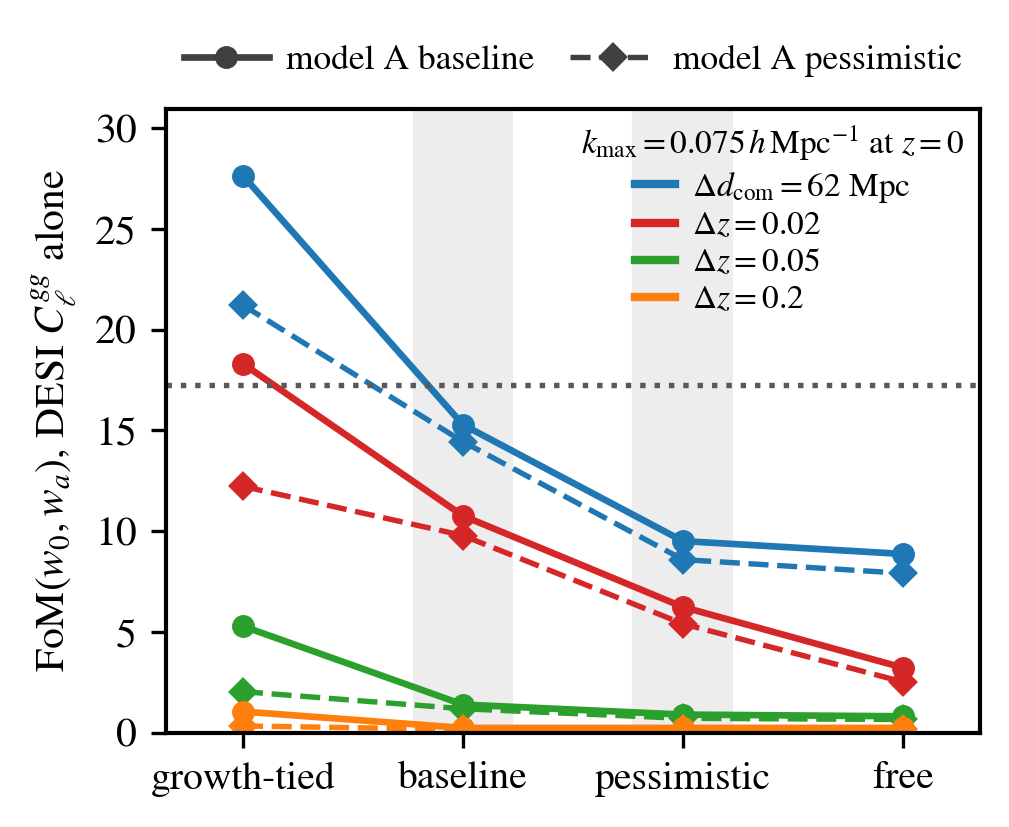

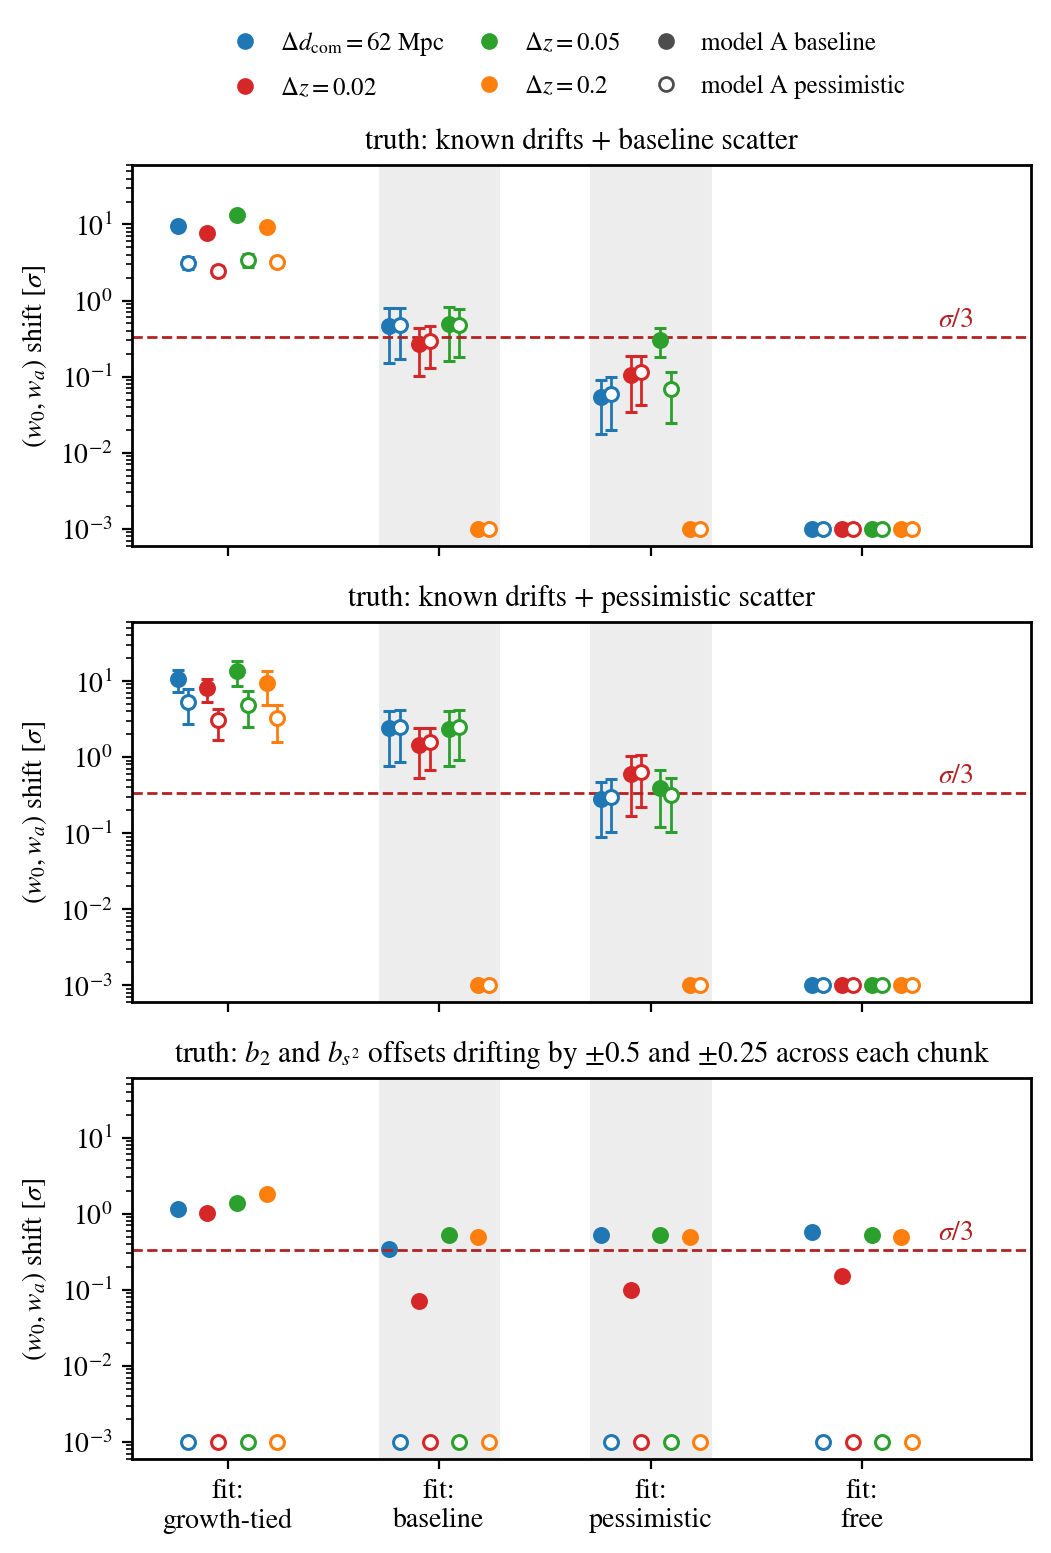

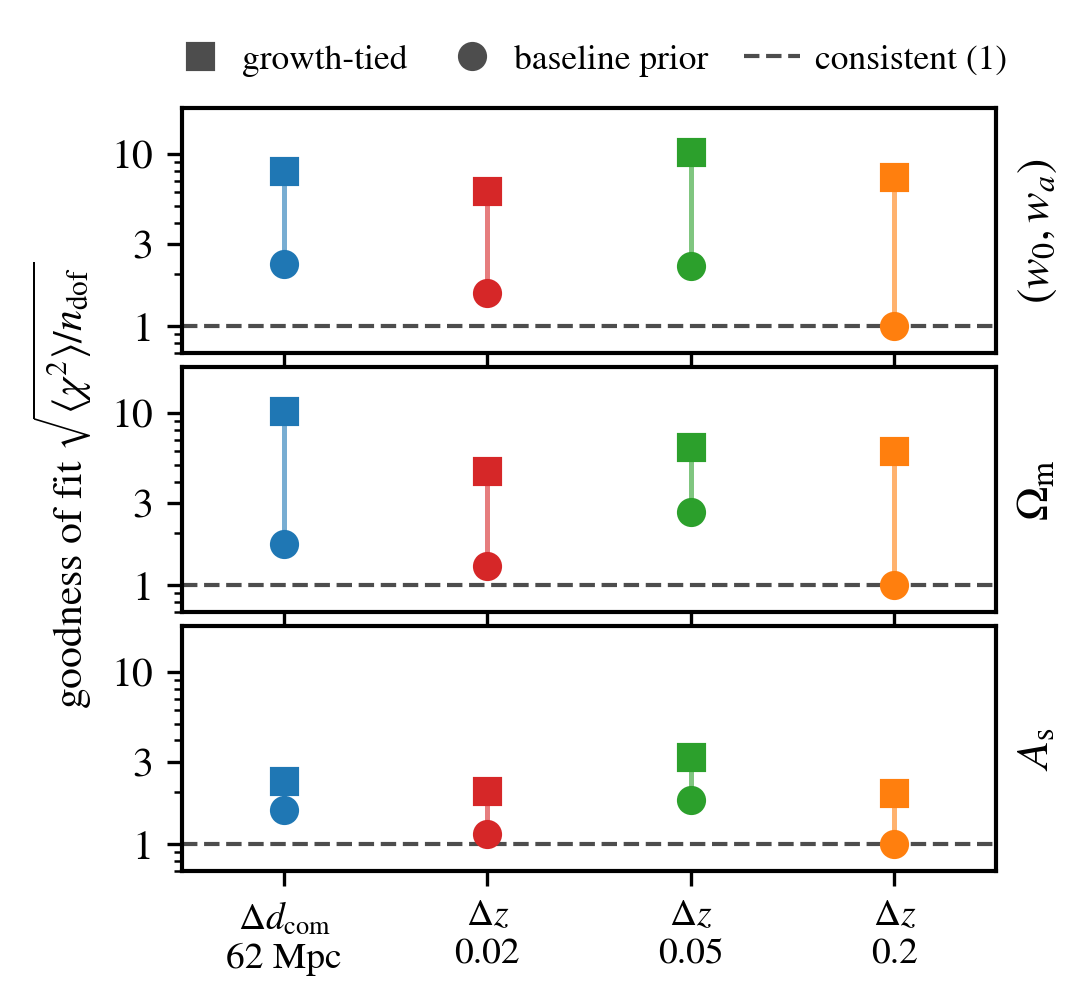

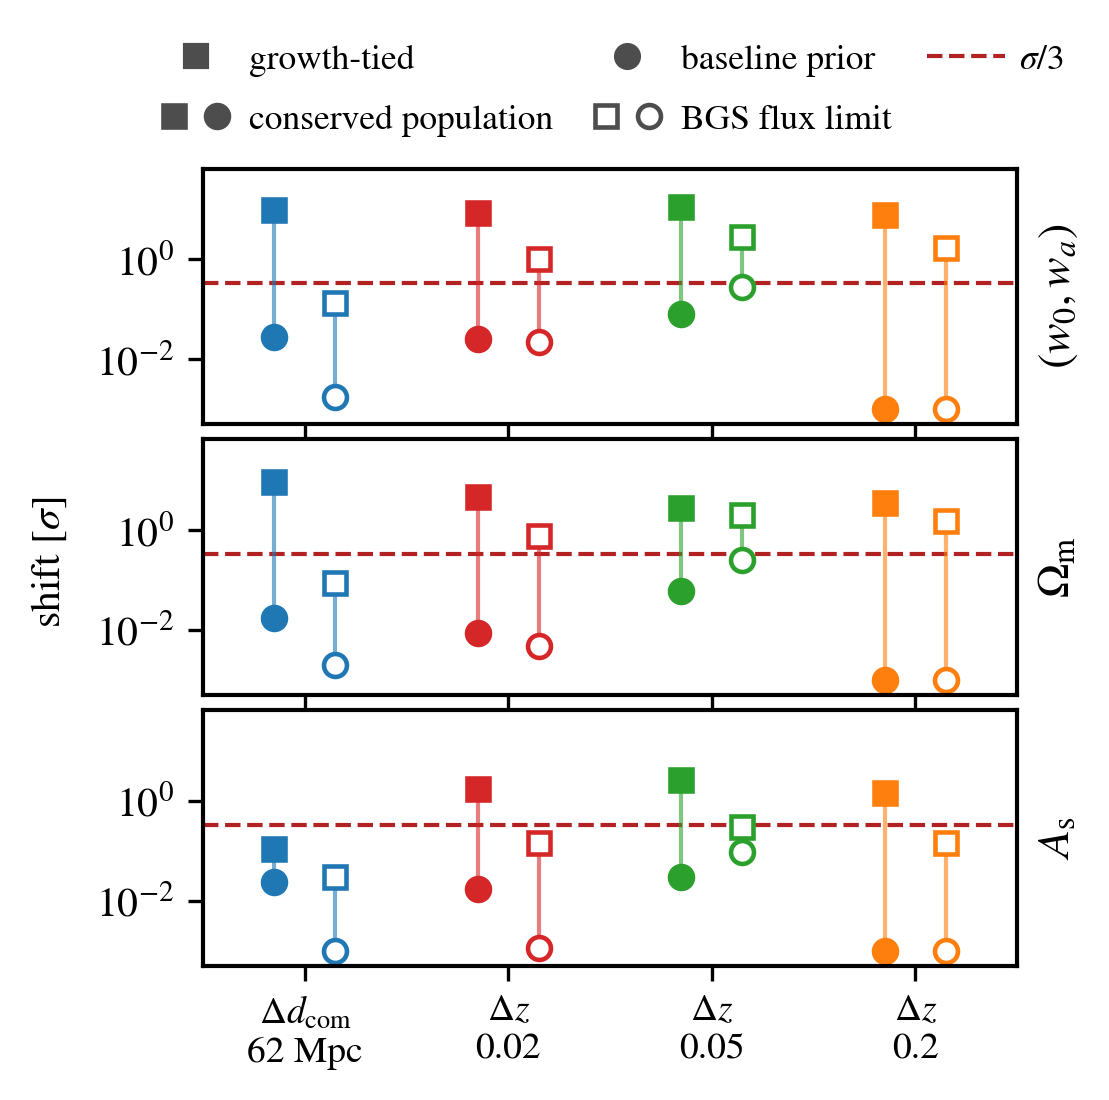

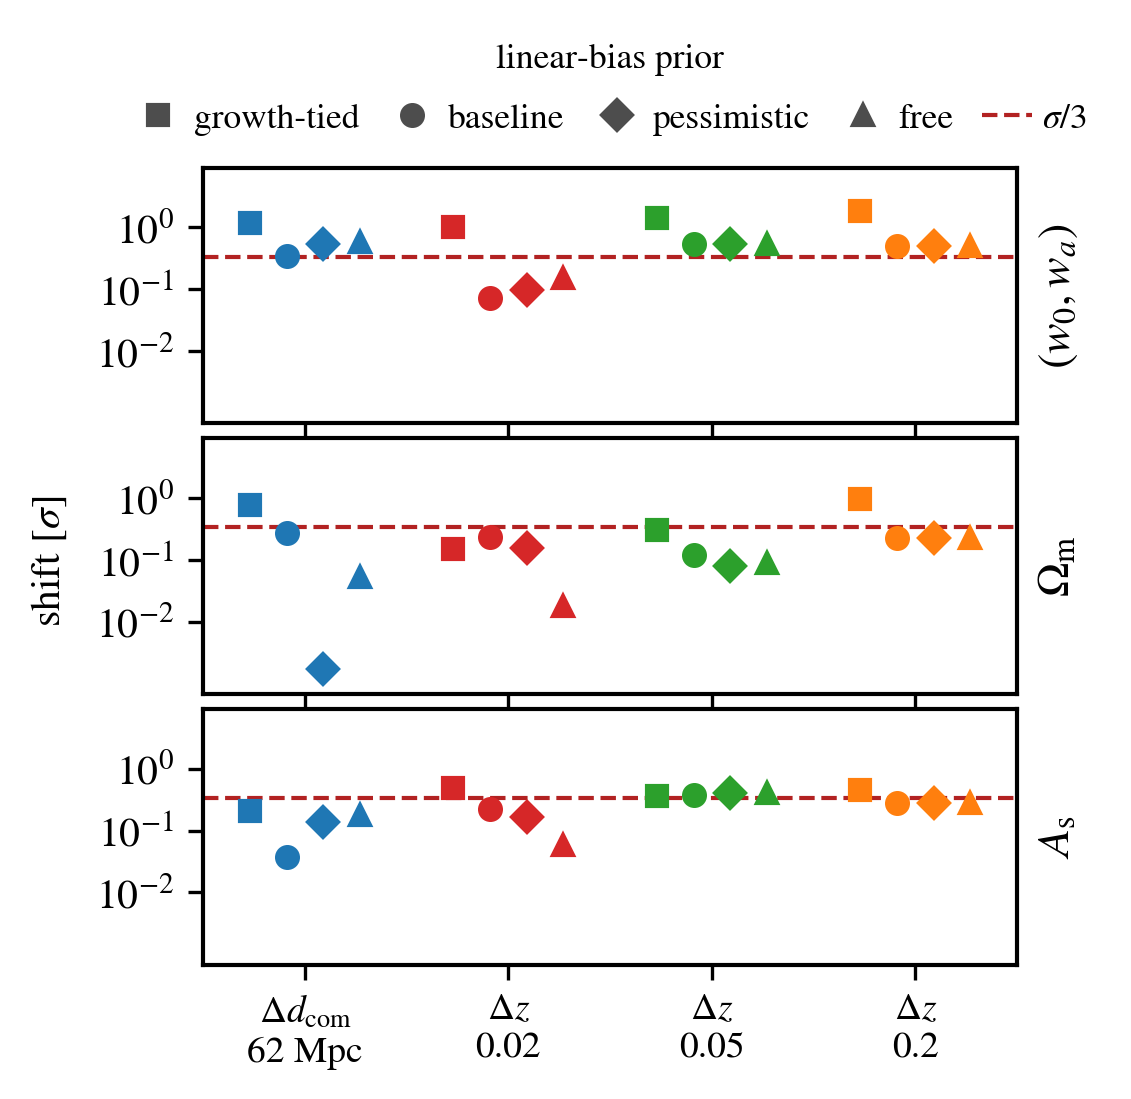

In [9]:
RUNG_LABELS = [{'key': 'tied', 'label': 'tied'}, {'key': 'baseline', 'label': 'baseline'},
               {'key': 'pessimistic', 'label': 'pessimistic'},
               {'key': 'independent', 'label': 'independent'}]
common = {
    'kmax_h_per_Mpc': KMAX, 'lsst_y1_3x2pt_fom': LSST_Y1_SRD_FOM,
    'shift_threshold': SHIFT_THRESHOLD, 'rungs': RUNG_LABELS,
    'variants': HO_VARIANTS,
    'priors': {case: {'model': 'memory', 'L': p['L'], 'sigma_b': p['sigma_b']}
               for case, p in BIAS_ASSUMPTIONS.items()},
    'model_a_priors': MODEL_A_PRIOR, 'single_params': SINGLE_PARAMS,
}
ladder_data = {
    'about': ('FoM(w0, wa) of DESI C_gg alone at k_max on the rungs of the linear-bias '
              'ladder under model A (notes/higher_order_bias) for three higher-order '
              'variants, with the v1 linear-bias values and the shifts of the known '
              'drifts. Written by EXAMPLE_EVALUATE_FISHER_MODEL_A.ipynb.'),
    **common,
    'layouts': [{'name': key, 'label': LAYOUT_LABELS[key], 'color': LAYOUT_COLORS[key],
                 'v1_linear': {r: V1_LADDER[key]['fom'][r] for r in LADDER_RUNGS},
                 'fom_om_as': {v: {r: ladder[(key, v, r)]['fom_om_as'] for r in LADDER_RUNGS}
                               for v in HO_VARIANTS},
                 'fom': {v: {r: ladder[(key, v, r)]['fom'] for r in LADDER_RUNGS}
                         for v in HO_VARIANTS},
                 # per drift law: the (w0, wa) shift in its ellipse
                 # ('conserved', 'flux_limit') and the single-parameter
                 # shifts in their own sigma ('conserved_omegam', ...)
                 'shifts': {v: {r: {k: val for k, val in ladder[(key, v, r)].items()
                                    if k not in ('fom', 'fom_om_as')}
                                for r in LADDER_RUNGS}
                            for v in HO_VARIANTS}}
                for key in LAYOUTS],
}
scatter_data = {
    'about': ('the random-truth accuracy test of the v1 note under model A: truths = '
              'known drifts plus a baseline or pessimistic residual (same draws as v1, '
              'b2 and bs2 following b1), fitted with every linear rung and higher-order '
              'variant; mean and 16-84 percentiles of the (w0, wa) shift in units of '
              'each fit\'s ellipse, and the goodness of fit sqrt(E[chi2_w]/2) (stored as '
              'error_inflation); plus the '
              'shift of a calibration drift of the b2 and bs2 offsets. Written by '
              'EXAMPLE_EVALUATE_FISHER_MODEL_A.ipynb.'),
    **common, 'n_draws': SCATTER_DRAWS, 'truths': list(BIAS_ASSUMPTIONS),
    'calibration_drift': CAL_DRIFT,
    'layouts': [{'name': key, 'label': LAYOUT_LABELS[key], 'color': LAYOUT_COLORS[key],
                 'fits': {v: {r: scatter[(key, v, r)] for r in LADDER_RUNGS}
                          for v in HO_VARIANTS}}
                for key in LAYOUTS],
}
# The three compact single-column figures: the goodness of fit of the
# random-truth test, and the shifts of the known drifts and of the
# calibration drift, each for (w0, wa), Omega_m and A_s and for the two
# forecast variants (the figures draw model A baseline; the captions quote
# the other values from these files).
FORECAST_VARIANTS = ['A baseline', 'A pessimistic']
SCORED = ['w0wa', *SINGLE_PARAMS]


def layout_entry(key):
    return {'name': key, 'label': LAYOUT_LABELS[key], 'color': LAYOUT_COLORS[key]}


def scored(w0wa, single):
    '''{score: value} from the (w0, wa) value and a {param: value} getter.'''
    return {'w0wa': w0wa, **{p: single(p) for p in SINGLE_PARAMS}}


compact = {'kmax_h_per_Mpc': KMAX, 'shift_threshold': SHIFT_THRESHOLD, 'params': SCORED,
           'rungs': LADDER_RUNGS, 'variants': FORECAST_VARIANTS}
gof_data = {
    'about': ('goodness of fit of the parameter recovery, sqrt(E[chi2]/n_dof): chi2 of the '
              'recovered (w0, wa) (n_dof = 2), Omega_m or A_s (n_dof = 1) against the truth '
              'in units of the fit\'s own covariance, averaged over the random truths of the '
              'v1 test and the data noise; 1 when the error bars cover the truth as they '
              'claim. Written by EXAMPLE_EVALUATE_FISHER_MODEL_A.ipynb.'),
    **compact, 'truths': list(BIAS_ASSUMPTIONS),
    'layouts': [{**layout_entry(key), 'gof': {v: {t: {r: scored(
        scatter[(key, v, r)][t]['error_inflation'],
        lambda p: scatter[(key, v, r)][t][p]['error_inflation'])
        for r in LADDER_RUNGS} for t in BIAS_ASSUMPTIONS} for v in FORECAST_VARIANTS}}
        for key in LAYOUTS],
}
drift_data = {
    'about': ('the shift of a fit to each known drift of the linear bias (b2 and bs2 '
              'following b1): (w0, wa) in units of the fit\'s ellipse, Omega_m and A_s in '
              'their own sigma. Written by EXAMPLE_EVALUATE_FISHER_MODEL_A.ipynb.'),
    **compact, 'drifts': DRIFT_LAWS,
    'layouts': [{**layout_entry(key), 'shift': {v: {law: {r: scored(
        ladder[(key, v, r)][law], lambda p: ladder[(key, v, r)][f'{law}_{p}'])
        for r in LADDER_RUNGS} for law in DRIFT_LAWS} for v in FORECAST_VARIANTS}}
        for key in LAYOUTS],
}
cal_data = {
    'about': ('the shift of a fit to the calibration drift (b2 and bs2 offsets linear in '
              'redshift across each chunk, b1 at its fiducial): (w0, wa) in units of the '
              'fit\'s ellipse, Omega_m and A_s in their own sigma. Written by '
              'EXAMPLE_EVALUATE_FISHER_MODEL_A.ipynb.'),
    **compact, 'calibration_drift': CAL_DRIFT,
    'layouts': [{**layout_entry(key), 'shift': {v: {r: scored(
        scatter[(key, v, r)]['calibration_drift']['shift'],
        lambda p: scatter[(key, v, r)]['calibration_drift'][p])
        for r in LADDER_RUNGS} for v in FORECAST_VARIANTS}}
        for key in LAYOUTS],
}
for name, data in (('baseline_ladder', ladder_data), ('ladder_bias_scatter', scatter_data),
                   ('goodness_of_fit', gof_data), ('drift_shifts', drift_data),
                   ('calibration_drift', cal_data)):
    os.makedirs(NOTE_PLOTS + name, exist_ok=True)
    with open(NOTE_PLOTS + name + '/data.json', 'w') as f:
        json.dump(data, f, indent=1)
    script = NOTE_PLOTS + name + f'/plot_{name}.py'
    if os.path.exists(script):
        subprocess.run([sys.executable, script], check=True)
        display(Image(filename=NOTE_PLOTS + name + f'/{name}.png', width=640))

## 9. Conclusion

The v2 note quotes the forecast as a ladder of two stated configurations, as v1
does for linear bias:

- **reasonable**: model A baseline on the baseline prior,
  ${\rm FoM} = 15.3$, $10.8$, $1.39$ and $0.228$ ($\Delta d_\mathrm{com} = 62$ Mpc,
  $\Delta z = 0.02$, $0.05$, $0.2$). It assumes that each bin's linear-bias
  residual is no larger and no rougher than the baseline prior, and that the
  calibrations of $b_2$ and $b_{s^2}$ hold within a group up to one constant
  offset;
- **pessimistic**: model A pessimistic on the pessimistic prior,
  ${\rm FoM} = 8.59$, $5.40$, $0.705$ and $0.154$. It is honest under both families
  of random truths and absorbs a linear calibration drift exactly.

The growth-tied prior is excluded under both variants. The v1 and model A calibrated
rows printed above are diagnostics, not results: Figure 1 and the note's results
are model A baseline and model A pessimistic only. The absolute FoMs carry the covariance's linear bias
and its bias mismatch (a factor of about 2.4–3.2); the comparisons between priors
and variants hold the covariance fixed. The v2 note's appendices hold the full
tables, the numerical checks and the open questions about the counterterm.

All $k_\mathrm{max}$ above are quoted at $z = 0$; each bin is cut by the
UV-fraction criterion at $k_\mathrm{max}/D(\bar z_i)$ ($\alpha = 0.05$) within the
shipped mask.